# 02 — ACS Vulnerability Index

Fetches ACS 5-year estimates for Snohomish County block groups and builds
a composite vulnerability index from four normalized sub-indicators.

**Requires:** `CENSUS_API_KEY` in environment or `.env`

**Output:** `data/processed/vulnerability_index.gpkg`

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

from dotenv import load_dotenv
load_dotenv('../.env')  # loads CENSUS_API_KEY

import os
assert os.environ.get('CENSUS_API_KEY'), "Set CENSUS_API_KEY in .env before running this notebook."

from transit_gaps.vulnerability import fetch_acs, build_vulnerability_index

In [2]:
# Pull raw ACS data — takes ~30s depending on Census API
acs_df = fetch_acs(vintage=2023)
print(f"Block groups: {len(acs_df)}")
acs_df.head()

Querying Census API for 22 variables at block group level...
Done in 1.9s — 575 block groups returned.
Block groups: 575


,total_pop,m_65_66,m_67_69,m_70_74,m_75_79,m_80_84,m_85plus,f_65_66,f_67_69,f_70_74,...,total_occ_units,renter_no_vehicle,owner_no_vehicle,in_labor_force,unemployed,GEO_ID,state,county,tract,block group
0,1245,0,41,66,17,27,11,7,71,37,...,553,0,0,728,13,1500000US530610401001,53,061,040100,1
1,1876,0,9,10,16,18,0,83,24,0,...,611,0,24,1082,47,1500000US530610401002,53,061,040100,2
2,1166,2,40,44,21,0,55,10,13,30,...,508,0,7,601,22,1500000US530610401003,53,061,040100,3
3,483,0,0,0,0,0,0,0,0,0,...,0,0,0,30,0,1500000US530610401004,53,061,040100,4
4,1135,0,38,0,0,0,0,0,34,9,...,356,0,0,417,16,1500000US530610402001,53,061,040200,1


In [3]:
import cenpy                                                      
print(dir(cenpy.tiger))

['ESRILayer', 'GeoDataFrame', 'TigerConnection', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_basequery', '_baseurl', '_bcs', '_jget', '_pcs', 'available', 'copy', 'diter', 'gpsr', 'pd', 'r']


In [4]:
tiger = cenpy.tiger.TigerConnection('tigerWMS_ACS2023')           
print(tiger.layers)

[(ESRILayer) 2020 Census Public Use Microdata Areas, (ESRILayer) 2020 Census Public Use Microdata Areas Labels, (ESRILayer) 2020 Census ZIP Code Tabulation Areas, (ESRILayer) 2020 Census ZIP Code Tabulation Areas Labels, (ESRILayer) Tribal Census Tracts, (ESRILayer) Tribal Census Tracts Labels, (ESRILayer) Tribal Block Groups, (ESRILayer) Tribal Block Groups Labels, (ESRILayer) Census Tracts, (ESRILayer) Census Tracts Labels, (ESRILayer) Census Block Groups, (ESRILayer) Census Block Groups Labels, (ESRILayer) Unified School Districts, (ESRILayer) Unified School Districts Labels, (ESRILayer) Secondary School Districts, (ESRILayer) Secondary School Districts Labels, (ESRILayer) Elementary School Districts, (ESRILayer) Elementary School Districts Labels, (ESRILayer) School District Administrative Areas, (ESRILayer) School District Administrative Areas Labels, (ESRILayer) Estates, (ESRILayer) Estates Labels, (ESRILayer) County Subdivisions, (ESRILayer) County Subdivisions Labels, (ESRILaye

In [5]:
tiger = cenpy.tiger.TigerConnection('tigerWMS_ACS2023')
bg_layer = next(l for l in tiger.layers if l._name == 'Census Block Groups')                                            
print(bg_layer.variables[['name', 'type']])  

          name                   type
0        MTFCC    esriFieldTypeString
1          OID    esriFieldTypeString
2        GEOID    esriFieldTypeString
3        STATE    esriFieldTypeString
4       COUNTY    esriFieldTypeString
5        TRACT    esriFieldTypeString
6       BLKGRP    esriFieldTypeString
7     BASENAME    esriFieldTypeString
8         NAME    esriFieldTypeString
9        LSADC    esriFieldTypeString
10    FUNCSTAT    esriFieldTypeString
11    AREALAND    esriFieldTypeDouble
12   AREAWATER    esriFieldTypeDouble
13  STGEOMETRY  esriFieldTypeGeometry
14     CENTLAT    esriFieldTypeString
15     CENTLON    esriFieldTypeString
16    INTPTLAT    esriFieldTypeString
17    INTPTLON    esriFieldTypeString
18    OBJECTID       esriFieldTypeOID


In [6]:
# Build composite index with default equal weights
vuln_gdf = build_vulnerability_index(                             
  acs_df=acs_df,                                                
  out_path='../data/processed/vulnerability_index.gpkg'
)                                                                 


TIGER GEOID sample: '530610527084'
ACS GEOID sample:   '530610401001'
Merged: 575/575 block groups matched
Saved vulnerability index → ../data/processed/vulnerability_index.gpkg  (575 block groups)


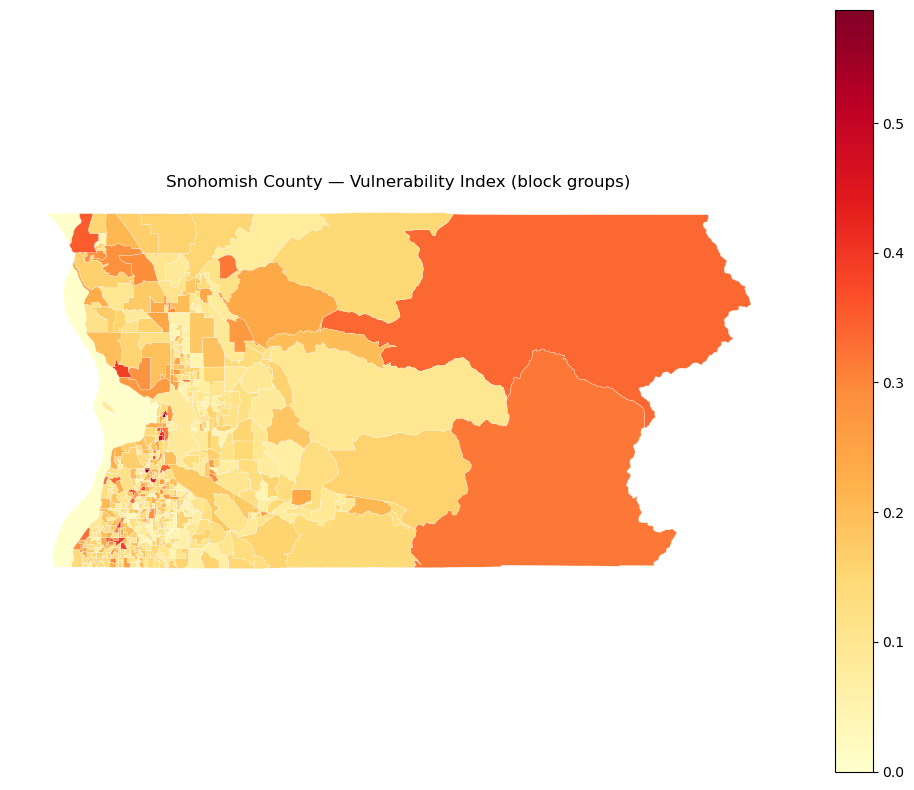

In [7]:
# QA: choropleth of vulnerability index
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
vuln_gdf.plot(
    column='vulnerability_index',
    cmap='YlOrRd',
    legend=True,
    linewidth=0.2,
    edgecolor='white',
    ax=ax,
    missing_kwds={'color': 'lightgray', 'label': 'No data'}
)
ax.set_title('Snohomish County — Vulnerability Index (block groups)')
ax.set_axis_off()
plt.tight_layout()
plt.show()

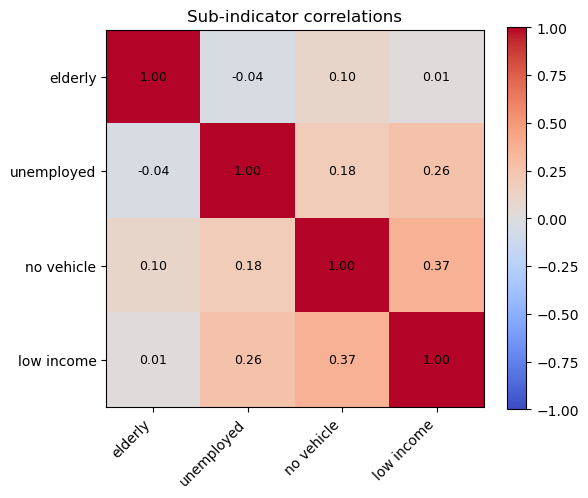

In [8]:
# QA: correlation between sub-indicators
import matplotlib.pyplot as plt
import numpy as np

sub = vuln_gdf[['pct_elderly', 'pct_unemployed', 'pct_novehicle', 'pct_lowincome']].dropna()
corr = sub.corr().values
labels = ['elderly', 'unemployed', 'no vehicle', 'low income']

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('Sub-indicator correlations')
plt.tight_layout()
plt.show()

TIGER GEOID sample: '530610527084'
ACS GEOID sample:   '530610401001'
Merged: 575/575 block groups matched
Saved vulnerability index → /tmp/vuln_elderly_heavy.gpkg  (575 block groups)
                  equal  elderly_heavy
equal          1.000000       0.951942
elderly_heavy  0.951942       1.000000


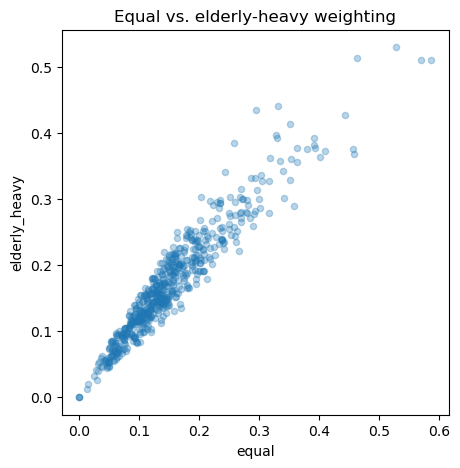

In [9]:
# Sensitivity: compare equal-weight vs elderly-heavy weights
from transit_gaps.vulnerability import build_vulnerability_index

vuln_elderly = build_vulnerability_index(
    acs_df=acs_df,
    out_path='/tmp/vuln_elderly_heavy.gpkg',
    weights={'elderly': 0.4, 'unemployed': 0.2, 'novehicle': 0.2, 'lowincome': 0.2}
)

import pandas as pd
compare = pd.DataFrame({
    'equal': vuln_gdf.set_index('GEOID')['vulnerability_index'],
    'elderly_heavy': vuln_elderly.set_index('GEOID')['vulnerability_index']
})
print(compare.corr())
compare.plot.scatter(x='equal', y='elderly_heavy', alpha=0.3, figsize=(5, 5))
plt.title('Equal vs. elderly-heavy weighting')
plt.show()